In [441]:
import matplotlib.pyplot as plt
import pandas as pd
df=pd.read_csv("bank.csv", sep=";")

In [442]:
df.head(5) 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [443]:
df.shape

(4521, 17)

In [444]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [445]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [446]:
df.describe(include="object")

C:\Users\Dr.P\AppData\Local\Temp\ipykernel_3404\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [447]:
print(df.isna().sum())
print(df.isnull().mean()*100)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
y            0.0
dtype: float64


In [448]:
df["poutcome"].value_counts(dropna=False)

poutcome
unknown    3705
failure     490
other       197
success     129
Name: count, dtype: int64

In [449]:
df["contact"].value_counts(dropna=False)

contact
cellular     2896
unknown      1324
telephone     301
Name: count, dtype: int64

In [450]:
df["education"].value_counts(dropna=False)

education
secondary    2306
tertiary     1350
primary       678
unknown       187
Name: count, dtype: int64

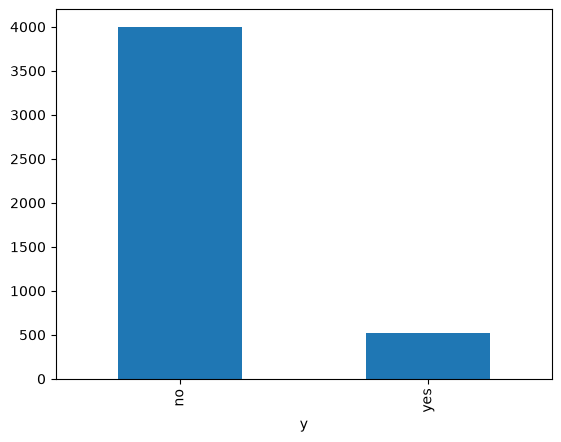

In [451]:
df["y"].value_counts().plot(kind="bar")
plt.show()

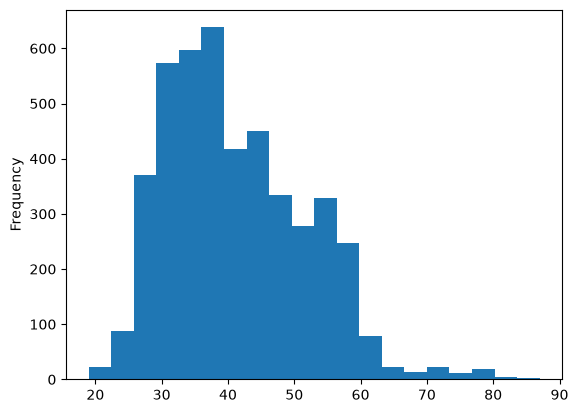

In [452]:
df["age"].plot(kind="hist",bins=20)
plt.show()


In [453]:
df.duplicated().sum()

np.int64(0)

In [455]:
df["job"].value_counts()

job
management       969
blue-collar      946
technician       768
admin.           478
services         417
retired          230
self-employed    183
entrepreneur     168
unemployed       128
housemaid        112
student           84
unknown           38
Name: count, dtype: int64

In [456]:
df["y"].unique()

<StringArray>
['no', 'yes']
Length: 2, dtype: str

In [457]:
df["y"] = df["y"].map({"no" : 0 , "yes": 1})

In [458]:
print(df["y"].unique())
print(df["y"].value_counts(dropna=False))

[0 1]
y
0    4000
1     521
Name: count, dtype: int64


In [459]:
df.corr(numeric_only=True)["y"].sort_values(ascending=False)

y           1.000000
duration    0.401118
previous    0.116714
pdays       0.104087
age         0.045092
balance     0.017905
day        -0.011244
campaign   -0.061147
Name: y, dtype: float64

In [460]:
x = df.drop(columns=["y","duration"])
y= df["y"]

In [461]:
x.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'poutcome'],
      dtype='str')

In [462]:
df.corr(numeric_only=True)["y"].sort_values(ascending=False)

y           1.000000
duration    0.401118
previous    0.116714
pdays       0.104087
age         0.045092
balance     0.017905
day        -0.011244
campaign   -0.061147
Name: y, dtype: float64

In [463]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y
)

In [464]:
num_cols = ["age","day","balance","previous","campaign","pdays"]
cat_cols =["job", "marital" , "default" , "housing" , "month" , "loan", "education","contact","poutcome"]

In [465]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [466]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("Scaler" , StandardScaler())

])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])



In [467]:
preproccessor = ColumnTransformer([ 
    ("num" , num_pipe , num_cols),
    ("cat" , cat_pipe , cat_cols)
])

In [468]:
from sklearn.neighbors import KNeighborsClassifier

model = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classfier" , KNeighborsClassifier(n_neighbors=8))
])

In [469]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X_train, y_train , cv=5 , scoring="f1")

In [470]:
print(scores)
print (scores.mean())


[0.08510638 0.06741573 0.09090909 0.12765957 0.12765957]
0.09975007063221264


In [471]:
from sklearn.linear_model import LogisticRegression
model2 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classfier" , LogisticRegression(max_iter= 5000,class_weight="balanced"))
])

In [472]:
scores2 = cross_val_score(model2 , X_train , y_train , cv = 5 , scoring="f1")

In [473]:
print(scores2)
print (scores2.mean())


[0.34013605 0.28865979 0.34969325 0.33670034 0.30921053]
0.32487999255721406


In [474]:
from sklearn.tree import DecisionTreeClassifier
model3 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classfier" , DecisionTreeClassifier(random_state=42 , class_weight="balanced"))
])

In [475]:
scores3 = cross_val_score(model3 , X_train , y_train , cv = 5 , scoring="f1")

In [476]:
print(scores3)
print (scores3.mean())


[0.26829268 0.2        0.26589595 0.28901734 0.25698324]
0.25603784358959614


In [477]:
from sklearn.ensemble import RandomForestClassifier
model4 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classfier" , RandomForestClassifier(n_estimators=100,random_state=42, n_jobs=-1,class_weight="balanced"))
])


In [478]:
scores4 = cross_val_score(model4 , X_train , y_train , cv = 5 , scoring="f1")

In [479]:
print(scores4)
print (scores4.mean())


[0.36764706 0.31884058 0.34782609 0.37878788 0.33333333]
0.3492869875222816


In [480]:
from sklearn.svm import SVC

model5 = Pipeline([
    ("preprocessor", preproccessor),
    ("classifier", SVC(kernel="rbf", C=1, gamma="scale",class_weight="balanced"))
])

In [481]:
scores5 = cross_val_score(model5 , X_train , y_train , cv = 5 , scoring="f1")

In [482]:
print(scores5)
print (scores5.mean())


[0.33333333 0.3255814  0.36575875 0.33198381 0.42533937]
0.35639933114596745


In [483]:
from sklearn.ensemble import GradientBoostingClassifier
model6 = Pipeline([
    ("preprocessor", preproccessor),
    ("classifier", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42))
])


In [484]:
scores6 = cross_val_score(model6 , X_train , y_train , cv = 5 , scoring="f1")

In [485]:
print(scores6)
print (scores6.mean())


[0.28571429 0.23529412 0.34188034 0.26548673 0.24299065]
0.27427322502220214


In [486]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores["test_accuracy"].mean())
print("Precision:", scores["test_precision"].mean())
print("Recall:", scores["test_recall"].mean())
print("F1:", scores["test_f1"].mean())

Accuracy: 0.8857866623873821
Precision: 0.5690909090909091
Recall: 0.05513482501434308
F1: 0.09975007063221264


In [487]:

scores2 = cross_validate(
    model2,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores2["test_accuracy"].mean())
print("Precision:", scores2["test_precision"].mean())
print("Recall:", scores2["test_recall"].mean())
print("F1:", scores2["test_f1"].mean())

Accuracy: 0.71791644697126
Precision: 0.2243734879404661
Recall: 0.5899885255306941
F1: 0.32487999255721406


In [488]:


scores3 = cross_validate(
    model3,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores3["test_accuracy"].mean())
print("Precision:", scores3["test_precision"].mean())
print("Recall:", scores3["test_recall"].mean())
print("F1:", scores3["test_f1"].mean())

Accuracy: 0.8210693626158655
Precision: 0.2472011213601013
Recall: 0.26617900172117037
F1: 0.25603784358959614


In [489]:

scores4 = cross_validate(
    model4,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores4["test_accuracy"].mean())
print("Precision:", scores4["test_precision"].mean())
print("Recall:", scores4["test_recall"].mean())
print("F1:", scores4["test_f1"].mean())

Accuracy: 0.8783177827193324
Precision: 0.45713405641977073
Recall: 0.2829890992541595
F1: 0.3492869875222816


In [490]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score,f1_score , precision_score , accuracy_score 


In [491]:
y_proba = cross_val_predict(model4, X_train, y_train , cv=5 , method="predict_proba")[:,1]
threshold=0.5
y_pred = (y_proba >= threshold).astype(int)

In [492]:

print("recall" , recall_score(y_train , y_pred))
print("f1" , f1_score(y_train , y_pred))
print("prec" , precision_score(y_train , y_pred))
print("acc" , accuracy_score(y_train , y_pred))

recall 0.28776978417266186
f1 0.34782608695652173
prec 0.43956043956043955
acc 0.8755530973451328


In [493]:
y_proba = cross_val_predict(model6, X_train, y_train , cv=5 , method="predict_proba")[:,1]
threshold=0.5
y_pred = (y_proba >= threshold).astype(int)

In [494]:

print("recall" , recall_score(y_train , y_pred))
print("f1" , f1_score(y_train , y_pred))
print("prec" , precision_score(y_train , y_pred))
print("acc" , accuracy_score(y_train , y_pred))

recall 0.18225419664268586
f1 0.27586206896551724
prec 0.5671641791044776
acc 0.8896570796460177


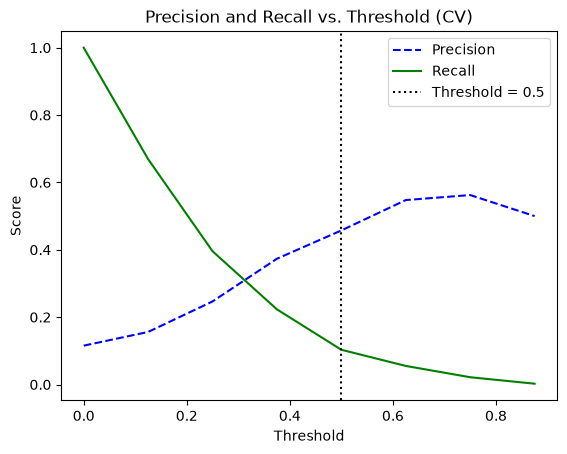

In [495]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

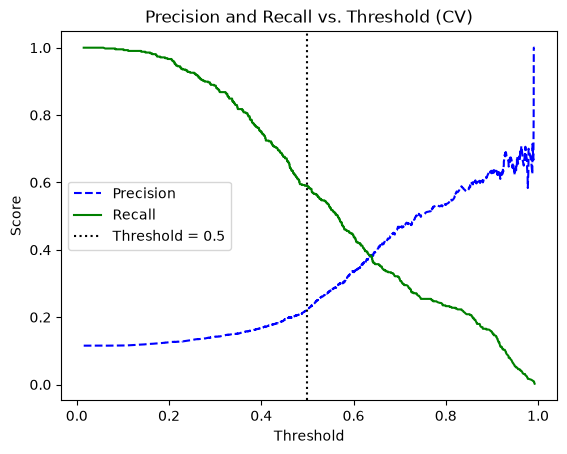

In [496]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model2,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

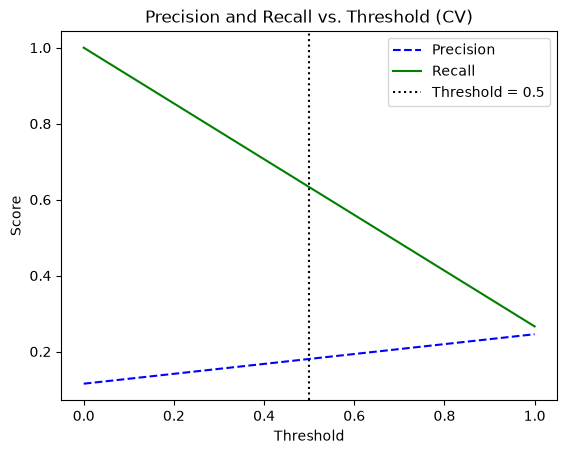

In [497]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model3,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

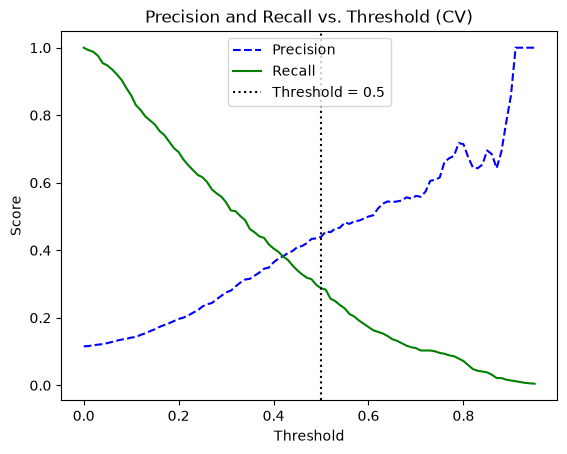

In [498]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model4,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

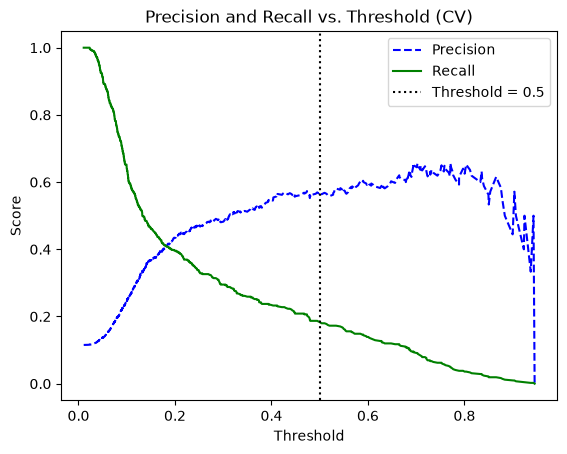

In [499]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model6,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()